# Siklus Halving & Power-Law Corridor (Rainbow Chart versi Quant)

Dua alat untuk membaca **posisi BTC di siklus jangka panjang** (bulan–tahun), terpisah dari model mingguan.

**Bagian 1 — Siklus halving.** Thesis populer: halving → top ±540 hari, top → bottom ±360 hari, top → top ±1.350 hari. Notebook ini:
- mendeteksi top & bottom tiap siklus **secara otomatis** dari data (bukan diketik manual),
- menghitung durasi & kelipatan harga tiap siklus,
- membuat **prediction interval** yang jujur untuk sampel sangat kecil (distribusi t),
- menguji mundur: seandainya metode ini dipakai di siklus sebelumnya, seberapa meleset?,
- memproyeksikan bottom siklus sekarang, halving berikutnya, dan top berikutnya.

**Bagian 2 — Power-law corridor.** Rainbow chart = regresi log harga vs log waktu + pita. Versi aslinya dipasang "pas di mata" dan digeser ulang setelah kejadian. Di sini:
- pita dibuat dengan **quantile regression** (bukan dipasang manual),
- posisi harian dihitung **walk-forward** (hanya pakai data sampai hari itu, tanpa hindsight),
- klaim "sentuh pita bawah = awal bull, sentuh pita atas = awal bear" **diuji** dengan data.

> **Kenapa bukan machine learning?** Siklus lengkap baru 3 kali. Dengan 3 titik data, model apa pun bisa "pas sempurna" tanpa arti. Yang jujur adalah statistik sampel kecil: rata-rata + interval lebar + uji mundur.

**Data:** harga harian BTC sejak 2010 dari **Coin Metrics Community API** (gratis, tanpa key; sumber yang sama dengan MVRV/SOPR di dataset kalian). Di Kaggle, aktifkan *Settings → Internet: On*. Cadangan: blockchain.com charts, atau CSV lokal (`LOCAL_PRICE_CSV`).

Semua harga = **close harian (UTC)**, jadi top/bottom bisa sedikit beda dari angka intraday yang sering dikutip (mis. top 2021 intraday $69K, close ±$67,5K).

## 0. Pengaturan

In [1]:
import os, json, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats
from sklearn.linear_model import QuantileRegressor

LOCAL_PRICE_CSV = None        # opsional: path CSV kolom (date, close). None = ambil dari API
CACHE_CSV = "btc_price_daily.csv"

GENESIS = pd.Timestamp("2009-01-03")
HALVINGS = [pd.Timestamp(d) for d in ["2012-11-28", "2016-07-09", "2020-05-11", "2024-04-20"]]
NEXT_HALVING_HEIGHT = 1_050_000
CURRENT_BLOCK_HEIGHT = None   # None = ambil otomatis (mempool.space / blockchain.info); isi manual (tinggi blok HARI INI) kalau gagal

MAJOR_TOP_DRAWDOWN = 0.60     # puncak = "top siklus" kalau setelahnya harga turun >= 60% sebelum tembus puncak itu lagi
TOP_CONFIRM_DRAWDOWN = 0.40   # top siklus BERJALAN dianggap terkonfirmasi (sementara) kalau sudah turun >= 40%
EXCLUDE_FIRST_CYCLE = False   # True = siklus 2013 (pasar masih sangat kecil) tidak dipakai untuk statistik durasi
SCALE_INFLATE = 1.0           # > 1 = lebarkan ketidakpastian untuk antisipasi pola berubah (coba 1.5)

PL_WF_START = pd.Timestamp("2012-01-01")   # awal walk-forward power-law (butuh ±1,5 tahun data pemanasan)
LOWER_PCT, UPPER_PCT = 10, 90               # definisi "menyentuh pita bawah / atas" (persentil corridor)
EPISODE_GAP_DAYS = 60                       # sentuhan baru dihitung episode baru kalau jeda >= 60 hari

## 1. Data Harga Harian

Urutan sumber: CSV lokal → cache → Coin Metrics → blockchain.com. Hasil disimpan ke `btc_price_daily.csv` supaya run berikutnya tidak perlu internet.

In [2]:
def from_coinmetrics():
    url = "https://community-api.coinmetrics.io/v4/timeseries/asset-metrics"
    params = {"assets": "btc", "metrics": "PriceUSD", "frequency": "1d",
              "start_time": "2010-07-01", "page_size": 10000}
    rows, nxt = [], None
    while True:
        r = requests.get(nxt or url, params=None if nxt else params, timeout=30)
        r.raise_for_status()
        j = r.json()
        rows += [(d["time"][:10], float(d["PriceUSD"])) for d in j["data"] if d.get("PriceUSD")]
        nxt = j.get("next_page_url")
        if not nxt:
            break
    return pd.Series(dict(rows), name="close")

def from_blockchain_com():
    r = requests.get("https://api.blockchain.info/charts/market-price",
                     params={"timespan": "all", "format": "json", "sampled": "false"}, timeout=30)
    r.raise_for_status()
    v = r.json()["values"]
    return pd.Series({pd.to_datetime(p["x"], unit="s").strftime("%Y-%m-%d"): p["y"] for p in v}, name="close")

def load_price():
    if LOCAL_PRICE_CSV and os.path.exists(LOCAL_PRICE_CSV):
        df = pd.read_csv(LOCAL_PRICE_CSV)
        s, src = pd.Series(df.iloc[:, 1].values, index=df.iloc[:, 0]), f"CSV lokal {LOCAL_PRICE_CSV}"
    elif os.path.exists(CACHE_CSV):
        s, src = pd.read_csv(CACHE_CSV, index_col=0)["close"], f"cache {CACHE_CSV}"
    else:
        s, src = None, None
        for name, fn in [("Coin Metrics", from_coinmetrics), ("blockchain.com", from_blockchain_com)]:
            try:
                s, src = fn(), name
                break
            except Exception as e:
                print(f"{name} gagal: {e}")
        if s is None:
            raise RuntimeError("Semua sumber gagal. Nyalakan internet Kaggle atau isi LOCAL_PRICE_CSV.")
    s.index = pd.to_datetime(s.index)
    s = s[s > 0].sort_index()
    s = s[~s.index.duplicated(keep="last")].asfreq("D").ffill()
    s.to_frame("close").to_csv(CACHE_CSV)
    return s.astype(float), src

price, price_src = load_price()
print(f"Sumber: {price_src} | {price.index.min().date()} -> {price.index.max().date()} | {len(price):,} hari")
TODAY = price.index.max()

Sumber: Coin Metrics | 2010-07-18 -> 2026-10-18 | 5,937 hari


# BAGIAN 1 — SIKLUS HALVING

## 1.1 Deteksi Top & Bottom per Siklus

Definisi (sama untuk semua siklus, tidak ada tanggal yang diketik manual):
- **Top siklus** = puncak all-time-high yang **diikuti penurunan ≥ `MAJOR_TOP_DRAWDOWN` (60%)** sebelum harga menembus puncak itu lagi. Puncak yang hanya diikuti koreksi kecil (mis. April 2021, −53%; Maret 2024 sebelum halving) tidak dihitung.
- Top dimasukkan ke siklus halving yang terjadi **sebelum** top itu. Kalau dalam satu siklus ada lebih dari satu (mis. April & Desember 2013), dipakai yang tertinggi.
- **Bottom** = close terendah setelah top, sebelum harga menembus top itu lagi.
- **Siklus berjalan:** top = all-time-high terakhir sejak halving; dianggap terkonfirmasi (sementara) kalau sudah turun ≥ `TOP_CONFIRM_DRAWDOWN`. Bottom-nya = "terendah sejauh ini", **belum** terkonfirmasi dan tidak dipakai di statistik.

Kenapa tidak "close tertinggi di antara dua halving"? Karena di siklus 2020–2024 harga sudah menembus top 2021 pada Maret 2024, sebelum halving. Definisi itu akan salah memilih Maret 2024 sebagai top siklus.

In [3]:
def find_major_tops(px, min_dd):
    """Puncak ATH yang diikuti penurunan >= min_dd sebelum ATH baru. Return (daftar top, puncak terbuka terakhir)."""
    tops = []
    peak_d, peak_p = px.index[0], px.iloc[0]
    trough_d, trough_p = peak_d, peak_p
    for d, p in px.items():
        if p > peak_p:
            if 1 - trough_p / peak_p >= min_dd:
                tops.append((peak_d, peak_p, trough_d, trough_p))
            peak_d, peak_p, trough_d, trough_p = d, p, d, p
        elif p < trough_p:
            trough_d, trough_p = d, p
    return tops, (peak_d, peak_p, trough_d, trough_p)

major, open_peak = find_major_tops(price, MAJOR_TOP_DRAWDOWN)
rows = []
for k, h in enumerate(HALVINGS, start=1):
    end = HALVINGS[k] if k < len(HALVINGS) else TODAY + pd.Timedelta(days=1)
    cand = [t for t in major if h <= t[0] < end]
    complete = bool(cand)
    if cand:
        top_d, top_p, bot_d, bot_p = max(cand, key=lambda t: t[1])
    elif k == len(HALVINGS) and open_peak[0] >= h:
        top_d, top_p, bot_d, bot_p = open_peak
    else:
        print(f"Siklus {k}: tidak ada top yang memenuhi definisi, dilewati")
        continue
    rows.append({"siklus": k, "halving": h, "top_date": top_d, "top_price": top_p,
                 "bottom_date": bot_d, "bottom_price": bot_p,
                 "top_confirmed": complete or (1 - bot_p / top_p) >= TOP_CONFIRM_DRAWDOWN,
                 "bottom_confirmed": complete})
cyc = pd.DataFrame(rows).set_index("siklus")

show = cyc.copy()
for c in ["halving", "top_date", "bottom_date"]:
    show[c] = show[c].dt.date
print(show.to_string())
cur = cyc.iloc[-1]
print(f"\nSiklus berjalan: top {cur.top_date.date()} (${cur.top_price:,.0f}) "
      f"{'TERKONFIRMASI' if cur.top_confirmed else 'BELUM terkonfirmasi'} | harga sekarang ${price.iloc[-1]:,.0f} "
      f"({price.iloc[-1] / cur.top_price - 1:+.1%} dari top) | terendah sejauh ini ${cur.bottom_price:,.0f} ({cur.bottom_date.date()})")

           halving    top_date      top_price bottom_date  bottom_price  top_confirmed  bottom_confirmed
siklus                                                                                                  
1       2012-11-28  2013-12-04    1134.932231  2015-01-14    175.637641           True              True
2       2016-07-09  2017-12-16   19640.513883  2018-12-15   3185.074044           True              True
3       2020-05-11  2021-11-08   67541.755508  2022-11-09  15758.291282           True              True
4       2024-04-20  2025-10-06  124824.453667  2026-06-30  58525.075361           True             False

Siklus berjalan: top 2025-10-06 ($124,824) TERKONFIRMASI | harga sekarang $81,935 (-34.4% dari top) | terendah sejauh ini $58,525 (2026-06-30)


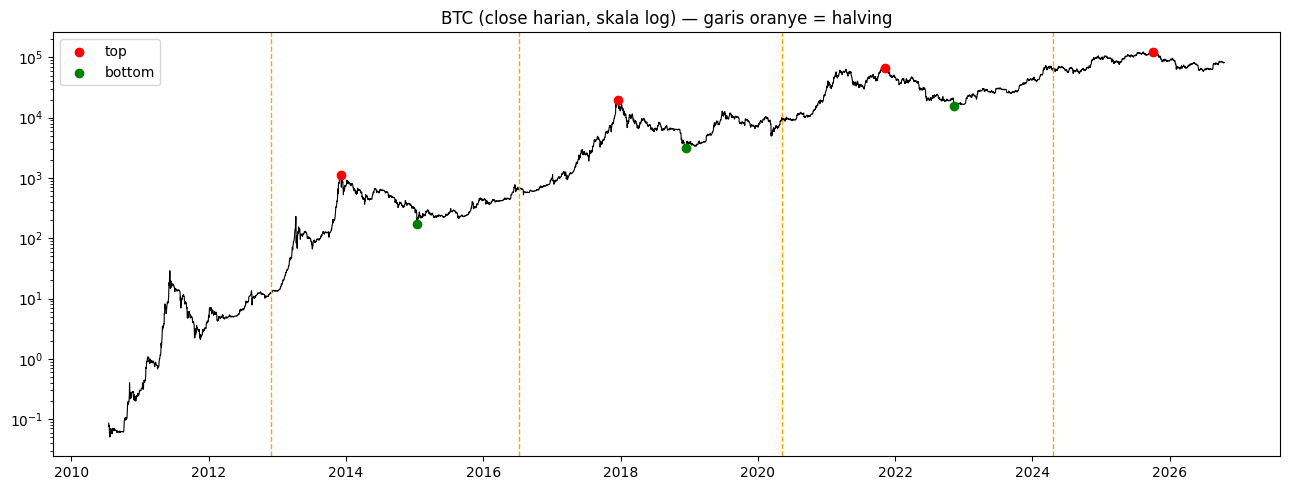

In [4]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.semilogy(price.index, price.values, lw=0.8, color="black")
for h in HALVINGS:
    ax.axvline(h, color="orange", ls="--", lw=1)
ax.scatter(cyc.top_date, cyc.top_price, color="red", zorder=5, label="top")
done = cyc[cyc.bottom_confirmed]
ax.scatter(done.bottom_date, done.bottom_price, color="green", zorder=5, label="bottom")
ax.set_title("BTC (close harian, skala log) — garis oranye = halving")
ax.legend(); plt.tight_layout(); plt.show()

## 1.2 Durasi & Kelipatan Harga + Prediction Interval

Untuk tiap ukuran, dihitung rata-rata dan **prediction interval** dari distribusi t:

`interval = rata-rata ± t(n−1) × sd × √(1 + 1/n)`

Ini sama dengan *posterior predictive* Bayesian dengan prior non-informatif. Dengan n = 3, pengali t untuk 95% adalah **4,30** (bukan 1,96). Interval yang lebar itulah jawaban jujur dari 3 data. `SCALE_INFLATE > 1` melebarkannya lagi untuk risiko pola berubah (mis. era ETF).

In [5]:
def predictive(values):
    x = np.asarray(values, float)
    n = len(x)
    if n < 2:
        return None
    return stats.t(df=n - 1, loc=x.mean(), scale=x.std(ddof=1) * np.sqrt(1 + 1 / n) * SCALE_INFLATE)

def summarize(name, values, labels, unit="hari"):
    d = predictive(values)
    row = {"ukuran": name, "nilai per siklus": ", ".join(f"{l}: {v:,.0f}" if unit == "hari" else f"{l}: {v:.2f}"
                                                        for l, v in zip(labels, values)),
           "n": len(values), "rata2": np.mean(values)}
    if d is not None:
        row["80% interval"] = f"{d.ppf(0.10):,.0f} – {d.ppf(0.90):,.0f}" if unit == "hari" else f"{d.ppf(0.10):.2f} – {d.ppf(0.90):.2f}"
        row["95% interval"] = f"{d.ppf(0.025):,.0f} – {d.ppf(0.975):,.0f}" if unit == "hari" else f"{d.ppf(0.025):.2f} – {d.ppf(0.975):.2f}"
    return row

use = cyc.iloc[1:] if EXCLUDE_FIRST_CYCLE else cyc
tops_ok = use[use.top_confirmed]
done = use[use.bottom_confirmed]

h2t = {k: (r.top_date - r.halving).days for k, r in tops_ok.iterrows()}
t2b = {k: (r.bottom_date - r.top_date).days for k, r in done.iterrows()}
t2t = {f"{a}→{b}": (cyc.loc[b, "top_date"] - cyc.loc[a, "top_date"]).days
       for a, b in zip(cyc.index[:-1], cyc.index[1:]) if a in tops_ok.index and cyc.loc[b, "top_confirmed"]}
b2t = {f"{a}→{b}": (cyc.loc[b, "top_date"] - cyc.loc[a, "bottom_date"]).days
       for a, b in zip(cyc.index[:-1], cyc.index[1:]) if a in done.index and cyc.loc[b, "top_confirmed"]}
mult = {f"{a}→{b}": cyc.loc[b, "top_price"] / cyc.loc[a, "top_price"]
        for a, b in zip(cyc.index[:-1], cyc.index[1:]) if a in tops_ok.index and cyc.loc[b, "top_confirmed"]}
dd = {k: (r.bottom_price / r.top_price - 1) * 100 for k, r in done.iterrows()}

table = pd.DataFrame([
    summarize("Halving → top", list(h2t.values()), list(h2t.keys())),
    summarize("Top → bottom", list(t2b.values()), list(t2b.keys())),
    summarize("Top → top", list(t2t.values()), list(t2t.keys())),
    summarize("Bottom → top berikutnya", list(b2t.values()), list(b2t.keys())),
    summarize("Kelipatan top baru ÷ top lama", list(mult.values()), list(mult.keys()), unit="x"),
    summarize("Drawdown top → bottom (%)", list(dd.values()), list(dd.keys()), unit="x"),
])
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 220)
print(table.to_string(index=False))
print("\nThesis populer: halving→top ±540 | top→bottom ±360 | top→top ±1.350 hari")

                       ukuran                   nilai per siklus  n       rata2    80% interval     95% interval
                Halving → top     1: 371, 2: 525, 3: 546, 4: 534  4  494.000000       343 – 645        201 – 787
                 Top → bottom             1: 406, 2: 364, 3: 366  3  378.666667       327 – 430        261 – 496
                    Top → top 1→2: 1,473, 2→3: 1,423, 3→4: 1,428  3 1441.333333   1,381 – 1,501    1,305 – 1,578
      Bottom → top berikutnya 1→2: 1,067, 2→3: 1,059, 3→4: 1,062  3 1062.666667   1,054 – 1,071    1,043 – 1,083
Kelipatan top baru ÷ top lama   1→2: 17.31, 2→3: 3.44, 3→4: 1.85  3    7.530819  -10.98 – 26.04   -34.71 – 49.77
    Drawdown top → bottom (%)    1: -84.52, 2: -83.78, 3: -76.67  3  -81.658784 -91.10 – -72.22 -103.21 – -60.11

Thesis populer: halving→top ±540 | top→bottom ±360 | top→top ±1.350 hari


## 1.3 Uji Mundur: Kalau Dipakai Dulu, Seberapa Meleset?

Untuk tiap siklus, tebak tanggal top/bottom-nya **hanya dari siklus-siklus sebelumnya**, lalu bandingkan dengan kenyataan. Tiga cara menebak top:
- **A. Top → top**: top sebelumnya + rata-rata jarak top-top sebelumnya.
- **B. Halving + jeda**: tanggal halving siklus itu + rata-rata jeda halving→top sebelumnya.
- **C. Bottom → top**: bottom sebelumnya + rata-rata jarak bottom→top sebelumnya.

Kolom `di dalam 80%?` = apakah kenyataan masuk interval 80% (hanya bisa dihitung kalau ada ≥ 2 data sebelumnya).

In [6]:
def loo_row(target, method, anchor, history, actual):
    pred = anchor + pd.Timedelta(days=float(np.mean(history)))
    d = predictive(history)
    inside = "-"
    if d is not None:
        off = (actual - anchor).days
        inside = "ya" if d.ppf(0.10) <= off <= d.ppf(0.90) else "TIDAK"
    return {"target": target, "metode": method, "n data": len(history), "tebakan": pred.date(),
            "aktual": actual.date(), "meleset (hari)": (actual - pred).days, "di dalam 80%?": inside}

bt = []
ks = list(cyc.index)
for i, k in enumerate(ks):
    prev = ks[:i]
    if not prev or not cyc.loc[k, "top_confirmed"]:
        continue
    actual_top = cyc.loc[k, "top_date"]
    hist_t2t = [(cyc.loc[b, "top_date"] - cyc.loc[a, "top_date"]).days for a, b in zip(prev[:-1], prev[1:])]
    if hist_t2t:
        bt.append(loo_row(f"top siklus {k}", "A. top→top", cyc.loc[prev[-1], "top_date"], hist_t2t, actual_top))
    hist_h2t = [(cyc.loc[p, "top_date"] - cyc.loc[p, "halving"]).days for p in prev]
    bt.append(loo_row(f"top siklus {k}", "B. halving + jeda", cyc.loc[k, "halving"], hist_h2t, actual_top))
    hist_b2t = [(cyc.loc[b, "top_date"] - cyc.loc[a, "bottom_date"]).days for a, b in zip(prev[:-1], prev[1:])]
    if hist_b2t:
        bt.append(loo_row(f"top siklus {k}", "C. bottom→top", cyc.loc[prev[-1], "bottom_date"], hist_b2t, actual_top))
    if cyc.loc[k, "bottom_confirmed"]:
        hist_t2b = [(cyc.loc[p, "bottom_date"] - cyc.loc[p, "top_date"]).days for p in prev]
        bt.append(loo_row(f"bottom siklus {k}", "top + jeda top→bottom", actual_top, hist_t2b, cyc.loc[k, "bottom_date"]))
bt = pd.DataFrame(bt)
print(bt.to_string(index=False))
print("\nRata-rata |meleset| per metode:")
print(bt.groupby("metode")["meleset (hari)"].apply(lambda s: s.abs().mean()).round(0).to_string())

         target                metode  n data    tebakan     aktual  meleset (hari) di dalam 80%?
   top siklus 2     B. halving + jeda       1 2017-07-15 2017-12-16             154             -
bottom siklus 2 top + jeda top→bottom       1 2019-01-26 2018-12-15             -42             -
   top siklus 3            A. top→top       1 2021-12-28 2021-11-08             -50             -
   top siklus 3     B. halving + jeda       2 2021-08-02 2021-11-08              98            ya
   top siklus 3         C. bottom→top       1 2021-11-16 2021-11-08              -8             -
bottom siklus 3 top + jeda top→bottom       2 2022-11-28 2022-11-09             -19            ya
   top siklus 4            A. top→top       2 2025-10-26 2025-10-06             -20            ya
   top siklus 4     B. halving + jeda       3 2025-08-13 2025-10-06              53            ya
   top siklus 4         C. bottom→top       2 2025-10-07 2025-10-06              -1            ya

Rata-rata |meleset|

## 1.4 Siklus Sekarang: Kapan & di Mana Bottom?

Proyeksi tanggal bottom = top siklus sekarang + distribusi jarak top→bottom dari siklus lengkap.
Tabel peluang = **"peluang bottom siklus ini jatuh sebelum tanggal X"** menurut pola historis. Ini bukan peluang harga, dan tidak tahu apakah bottom sudah terjadi.

Harga bottom memakai 3 skenario drawdown dari top (bukan interval, karena 3 data drawdown terlalu sedikit untuk interval yang bermakna).

Top siklus sekarang: 2025-10-06 ($124,824)
Perkiraan tengah bottom: 2026-10-19
  50% interval: 2026-09-27 -> 2026-11-11
  80% interval: 2026-08-29 -> 2026-12-10
  95% interval: 2026-06-23 -> 2027-02-14

            P(bottom sebelum tanggal ini)
2026-07-31                           0.05
2026-08-31                           0.11
2026-09-30                           0.27
2026-10-31                           0.64
2026-11-30                           0.87
2026-12-31                           0.94
2027-01-31                           0.97
2027-02-28                           0.98
2027-03-31                           0.99
2027-04-30                           0.99
2027-05-31                           0.99
2027-06-30                           0.99

Terendah sejauh ini: $58,525 pada 2026-06-30 (-53.1% dari top)

Skenario harga bottom:
  Sama dengan siklus terakhir : drawdown  -76.7% -> $29,123
  Rata-rata semua siklus      : drawdown  -81.7% -> $22,894
  Tren mengecil berlanjut     : drawdown  -

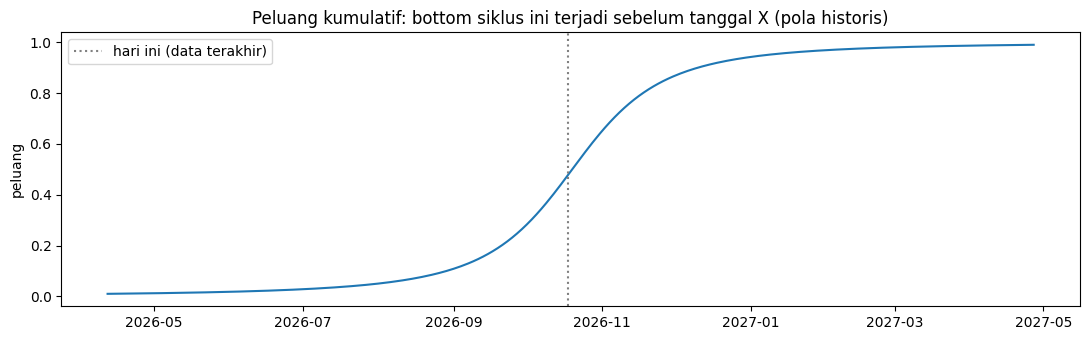

In [7]:
d_t2b = predictive(list(t2b.values()))
top_now, top_now_p = cur.top_date, cur.top_price
if not cur.top_confirmed:
    print("PERINGATAN: top siklus sekarang belum terkonfirmasi; proyeksi di bawah bisa bergeser.\n")

print(f"Top siklus sekarang: {top_now.date()} (${top_now_p:,.0f})")
print(f"Perkiraan tengah bottom: {(top_now + pd.Timedelta(days=d_t2b.median())).date()}")
for lvl in [0.5, 0.8, 0.95]:
    lo, hi = d_t2b.ppf((1 - lvl) / 2), d_t2b.ppf(1 - (1 - lvl) / 2)
    print(f"  {int(lvl*100)}% interval: {(top_now + pd.Timedelta(days=lo)).date()} -> {(top_now + pd.Timedelta(days=hi)).date()}")

checkpoints = pd.date_range(TODAY - pd.DateOffset(months=3), TODAY + pd.DateOffset(months=9), freq="ME")
cdf = pd.DataFrame({"P(bottom sebelum tanggal ini)": [d_t2b.cdf((c - top_now).days) for c in checkpoints]},
                   index=checkpoints.date)
print("\n" + cdf.round(2).to_string())
print(f"\nTerendah sejauh ini: ${cur.bottom_price:,.0f} pada {cur.bottom_date.date()} ({cur.bottom_price / top_now_p - 1:+.1%} dari top)")

dd_vals = list(dd.values())
trend = np.polyfit(range(len(dd_vals)), dd_vals, 1)
scen = {"Sama dengan siklus terakhir": dd_vals[-1],
        "Rata-rata semua siklus": float(np.mean(dd_vals)),
        "Tren mengecil berlanjut": float(np.polyval(trend, len(dd_vals)))}
print("\nSkenario harga bottom:")
for k, v in scen.items():
    print(f"  {k:28s}: drawdown {v:6.1f}% -> ${top_now_p * (1 + v / 100):,.0f}")

days_axis = np.arange(int(d_t2b.ppf(0.01)), int(d_t2b.ppf(0.99)))
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot([top_now + pd.Timedelta(days=int(x)) for x in days_axis], d_t2b.cdf(days_axis))
ax.axvline(TODAY, color="gray", ls=":", label="hari ini (data terakhir)")
ax.set_title("Peluang kumulatif: bottom siklus ini terjadi sebelum tanggal X (pola historis)")
ax.set_ylabel("peluang"); ax.legend(); plt.tight_layout(); plt.show()

## 1.5 Halving Berikutnya & Top Berikutnya

Jadwal halving hampir pasti (tiap 210.000 blok), jadi tanggal halving berikutnya bisa dihitung dari tinggi blok sekarang × rata-rata waktu blok. Tiga rentang waktu blok dipakai: 9,6 / 9,85 / 10,0 menit (siklus 2020→2024 rata-rata ±9,87 menit).

Tanggal top berikutnya dihitung dengan dua cara yang saling mengecek:
- **B. halving berikutnya + jeda halving→top** (distribusi dari siklus terkonfirmasi),
- **A. top sekarang + jarak top→top**.

Harga top berikutnya = top sekarang × kelipatan. Kelipatan top terus mengecil (log-nya kira-kira separuh tiap siklus); skenario di bawah memakai pola itu.

In [8]:
height = CURRENT_BLOCK_HEIGHT
if height is None:
    for url in ["https://mempool.space/api/blocks/tip/height", "https://blockchain.info/q/getblockcount"]:
        try:
            height = int(requests.get(url, timeout=15).text.strip())
            print(f"Tinggi blok dari {url}: {height:,}")
            break
        except Exception as e:
            print(f"{url} gagal: {e}")
if height is None:
    raise RuntimeError("Tinggi blok tidak didapat. Isi CURRENT_BLOCK_HEIGHT manual (lihat dashboard Network / mempool.space).")

remaining = NEXT_HALVING_HEIGHT - height
ref = pd.Timestamp.now(tz="UTC").tz_localize(None).normalize()   # tinggi blok = kondisi hari ini
halving_est = {m: ref + pd.Timedelta(minutes=remaining * m) for m in [9.6, 9.85, 10.0]}
next_h = halving_est[9.85]
print(f"Sisa {remaining:,} blok -> halving ke-5 sekitar {next_h.date()} "
      f"(rentang {halving_est[9.6].date()} – {halving_est[10.0].date()})")

d_h2t = predictive(list(h2t.values()))
d_t2t = predictive(list(t2t.values()))
print("\nTop berikutnya (siklus 5):")
for name, anchor, d in [("B. halving + jeda", next_h, d_h2t), ("A. top→top", top_now, d_t2t)]:
    if d is None:
        continue
    print(f"  {name:18s}: tengah {(anchor + pd.Timedelta(days=d.median())).date()} | "
          f"80% {(anchor + pd.Timedelta(days=d.ppf(0.1))).date()} – {(anchor + pd.Timedelta(days=d.ppf(0.9))).date()}")

lm = np.log(list(mult.values()))
ratios = lm[1:] / lm[:-1] if len(lm) > 1 else np.array([np.nan])
scen_top = {"Kelipatan sama dengan siklus terakhir": np.exp(lm[-1]),
            "Pola mengecil (rasio rata-rata)": np.exp(lm[-1] * np.nanmean(ratios)),
            "Pola mengecil (rasio terkecil)": np.exp(lm[-1] * np.nanmin(ratios)),
            "Pola mengecil (rasio terbesar)": np.exp(lm[-1] * np.nanmax(ratios))}
print(f"\nLog kelipatan per siklus: {np.round(lm, 2)} | rasio antar siklus: {np.round(ratios, 2)}")
print("Skenario harga top berikutnya:")
for k, v in scen_top.items():
    print(f"  {k:40s}: {v:.2f}x -> ${top_now_p * v:,.0f}")

Tinggi blok dari https://mempool.space/api/blocks/tip/height: 972,106
Sisa 77,894 blok -> halving ke-5 sekitar 2028-04-03 (rentang 2028-03-21 – 2028-04-11)

Top berikutnya (siklus 5):
  B. halving + jeda : tengah 2029-08-10 | 80% 2029-03-12 – 2030-01-08
  A. top→top        : tengah 2029-09-16 | 80% 2029-07-18 – 2029-11-15

Log kelipatan per siklus: [2.85 1.24 0.61] | rasio antar siklus: [0.43 0.5 ]
Skenario harga top berikutnya:
  Kelipatan sama dengan siklus terakhir   : 1.85x -> $230,689
  Pola mengecil (rasio rata-rata)         : 1.33x -> $166,108
  Pola mengecil (rasio terkecil)          : 1.30x -> $162,875
  Pola mengecil (rasio terbesar)          : 1.36x -> $169,405


# BAGIAN 2 — POWER-LAW CORRIDOR

Model: `log10(harga) = a + b · log10(hari sejak genesis)`. Garis lurus di grafik log-log; kemiringan `b` disebut eksponen power-law.

## 2.1 Pita dari Quantile Regression (Seluruh Data — Hanya untuk Visual)

Pita persentil 5/25/50/75/95 dicari dengan quantile regression, bukan dipasang manual. Karena memakai **seluruh** data, pita ini mengandung hindsight → hanya untuk gambar. Angka untuk analisis ada di 2.2.

q=0.05: log10(harga) = -17.528 + 5.883 · log10(hari)
q=0.25: log10(harga) = -17.322 + 5.853 · log10(hari)
q=0.50: log10(harga) = -17.088 + 5.829 · log10(hari)
q=0.75: log10(harga) = -14.670 + 5.218 · log10(hari)
q=0.95: log10(harga) = -13.217 + 4.900 · log10(hari)


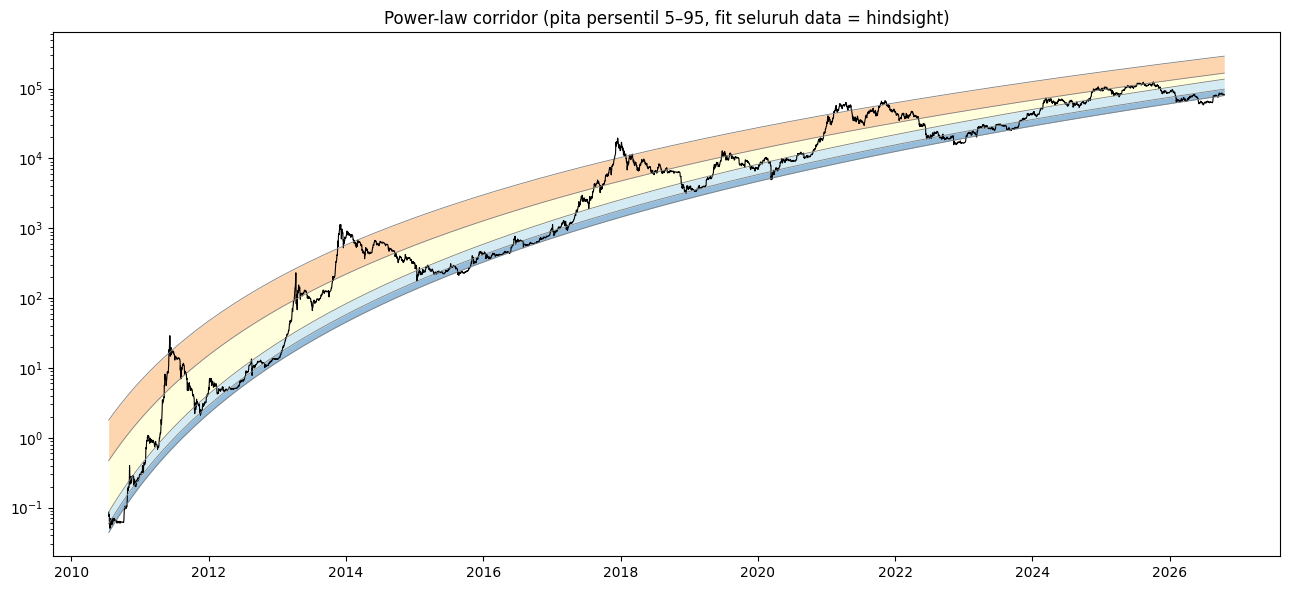

In [9]:
x_all = np.log10((price.index - GENESIS).days.values.astype(float))
y_all = np.log10(price.values)
QUANTS = [0.05, 0.25, 0.50, 0.75, 0.95]
qfit = {}
for q in QUANTS:
    m = QuantileRegressor(quantile=q, alpha=0, solver="highs").fit(x_all.reshape(-1, 1), y_all)
    qfit[q] = (m.intercept_, m.coef_[0])
    print(f"q={q:.2f}: log10(harga) = {m.intercept_:.3f} + {m.coef_[0]:.3f} · log10(hari)")

colors = ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"]
fig, ax = plt.subplots(figsize=(13, 6))
lines = {q: 10 ** (a + b * x_all) for q, (a, b) in qfit.items()}
for (q1, q2), c in zip(zip(QUANTS[:-1], QUANTS[1:]), colors):
    ax.fill_between(price.index, lines[q1], lines[q2], color=c, alpha=0.5, lw=0)
ax.semilogy(price.index, price.values, color="black", lw=0.8)
for q in QUANTS:
    ax.plot(price.index, lines[q], lw=0.6, color="gray")
ax.set_title("Power-law corridor (pita persentil 5–95, fit seluruh data = hindsight)")
plt.tight_layout(); plt.show()

## 2.2 Posisi Harian Walk-Forward (Tanpa Hindsight)

Tiap awal bulan: garis power-law di-fit ulang **hanya** dengan data sebelum tanggal itu, lalu posisi tiap hari di bulan itu = persentil selisih (harga − garis) dibanding semua selisih historis sampai saat itu.

Hasilnya angka 0–100 per hari: **"seberapa mahal BTC dibanding jalur jangka panjangnya, memakai informasi yang benar-benar tersedia saat itu"**.

| Persentil | Zona |
|---|---|
| 0–10 | Sangat murah |
| 10–30 | Murah |
| 30–70 | Wajar |
| 70–90 | Mahal |
| 90–100 | Sangat mahal (euforia) |

Eksponen b (walk-forward): 2014 = 6.54 | 2018 = 5.73 | terakhir = 5.64  -> kemiringan berubah seiring data bertambah

Posisi hari ini (2026-10-18): persentil 23 -> zona 'Murah'


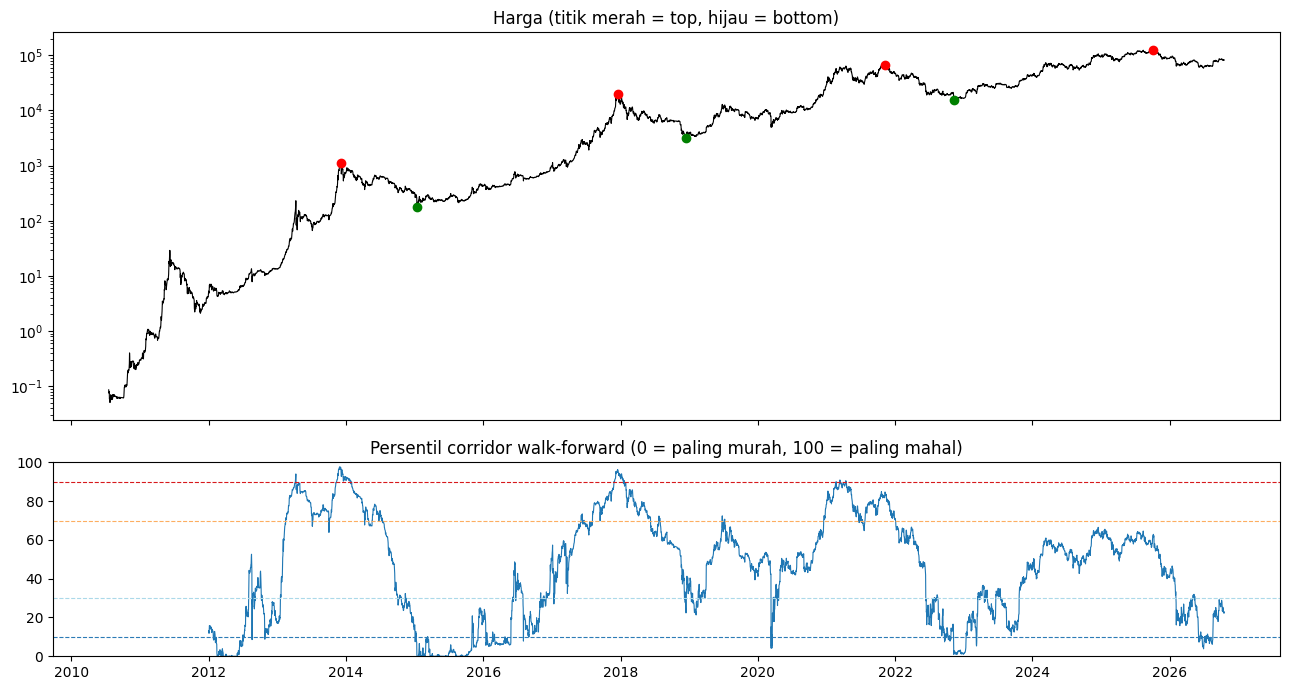


Persentil walk-forward di tiap top & bottom historis (dipakai untuk memilih pita proyeksi di 2.4):
 titik    tanggal  persentil
   top 2013-12-04       97.3
   top 2017-12-16       96.3
   top 2021-11-08       84.7
   top 2025-10-06       62.9
bottom 2015-01-14        0.0
bottom 2018-12-15       22.4
bottom 2022-11-09        1.0


In [10]:
idx = price.index
refits = pd.date_range(PL_WF_START, TODAY, freq="MS")
wf_pct = pd.Series(np.nan, index=idx)
fit_log = []
for i, R in enumerate(refits):
    past = idx < R
    b, a = np.polyfit(x_all[past], y_all[past], 1)
    resid = np.sort(y_all[past] - (a + b * x_all[past]))
    nxt = refits[i + 1] if i + 1 < len(refits) else TODAY + pd.Timedelta(days=1)
    blk = (idx >= R) & (idx < nxt)
    r_blk = y_all[blk] - (a + b * x_all[blk])
    wf_pct[blk] = np.searchsorted(resid, r_blk, side="right") / len(resid) * 100
    fit_log.append({"refit": R, "a": a, "b": b, "resid_q": np.quantile(resid, QUANTS)})
wf_pct = wf_pct.dropna()

def zone(p):
    return ("Sangat murah" if p < 10 else "Murah" if p < 30 else "Wajar" if p < 70
            else "Mahal" if p < 90 else "Sangat mahal")

fl = pd.DataFrame(fit_log).set_index("refit")
print(f"Eksponen b (walk-forward): 2014 = {fl.loc['2014-01-01', 'b']:.2f} | 2018 = {fl.loc['2018-01-01', 'b']:.2f} | "
      f"terakhir = {fl['b'].iloc[-1]:.2f}  -> kemiringan berubah seiring data bertambah")
print(f"\nPosisi hari ini ({TODAY.date()}): persentil {wf_pct.iloc[-1]:.0f} -> zona '{zone(wf_pct.iloc[-1])}'")

fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].semilogy(price.index, price.values, color="black", lw=0.8)
ax[0].scatter(cyc.top_date, cyc.top_price, color="red", zorder=5)
ax[0].scatter(cyc[cyc.bottom_confirmed].bottom_date, cyc[cyc.bottom_confirmed].bottom_price, color="green", zorder=5)
ax[0].set_title("Harga (titik merah = top, hijau = bottom)")
ax[1].plot(wf_pct.index, wf_pct.values, lw=0.8)
for lvl, c in [(10, "#2c7bb6"), (30, "#abd9e9"), (70, "#fdae61"), (90, "#d7191c")]:
    ax[1].axhline(lvl, color=c, ls="--", lw=0.8)
ax[1].set_ylim(0, 100); ax[1].set_title("Persentil corridor walk-forward (0 = paling murah, 100 = paling mahal)")
plt.tight_layout(); plt.show()

print("\nPersentil walk-forward di tiap top & bottom historis (dipakai untuk memilih pita proyeksi di 2.4):")
pts = [("top", r.top_date) for _, r in cyc.iterrows()] + \
      [("bottom", r.bottom_date) for _, r in cyc[cyc.bottom_confirmed].iterrows()]
print(pd.DataFrame([{"titik": t, "tanggal": d.date(), "persentil": round(wf_pct.get(d, np.nan), 1)} for t, d in pts]).to_string(index=False))

## 2.3 Uji Klaim "Sentuh Pita Bawah = Awal Bull, Sentuh Pita Atas = Awal Bear"

**Tes A — per zona:** untuk semua hari di tiap zona, berapa peluang harga 1 tahun kemudian lebih tinggi dan berapa median return-nya. (Hari-hari berurutan saling tumpang tindih, jadi `n hari` jauh lebih besar dari jumlah kejadian yang benar-benar independen.)

**Tes B — per episode:** "sentuhan" = hari pertama persentil ≤ `LOWER_PCT` (atau ≥ `UPPER_PCT`) setelah ≥ 60 hari tidak menyentuh. Untuk tiap episode: return 6 dan 12 bulan ke depan, kenaikan maksimum, dan penurunan maksimum dalam 12 bulan.

In [11]:
fwd365 = price.shift(-365) / price - 1
fwd180 = price.shift(-180) / price - 1
dfz = pd.DataFrame({"pct": wf_pct, "fwd365": fwd365.reindex(wf_pct.index)}).dropna()
dfz["zona"] = dfz["pct"].apply(zone)
order = ["Sangat murah", "Murah", "Wajar", "Mahal", "Sangat mahal"]
g = dfz.groupby("zona")
tabA = pd.DataFrame({"n hari": g.size(), "P(naik 1 tahun)": g["fwd365"].apply(lambda s: (s > 0).mean()),
                     "median return 1 thn": g["fwd365"].median()}).reindex(order)
print(f"Tes A (data {dfz.index.min().date()} -> {dfz.index.max().date()}; base rate semua hari: "
      f"P(naik) = {(dfz['fwd365'] > 0).mean():.2f}, median {dfz['fwd365'].median():+.0%})")
print(tabA.round(2).to_string())

def episode_starts(cond, gap=EPISODE_GAP_DAYS):
    starts, last = [], None
    for d in cond.index[cond.values]:
        if last is None or (d - last).days >= gap:
            starts.append(d)
        last = d
    return starts

def episode_table(starts):
    out = []
    for d in starts:
        p = price[d]
        nxt = price[(price.index > d) & (price.index <= d + pd.Timedelta(days=365))]
        out.append({"tanggal": d.date(), "harga": round(p), "persentil": round(wf_pct[d], 1),
                    "return 6 bln": fwd180.get(d), "return 12 bln": fwd365.get(d),
                    "naik maks 12 bln": nxt.max() / p - 1 if len(nxt) else np.nan,
                    "turun maks 12 bln": nxt.min() / p - 1 if len(nxt) else np.nan})
    return pd.DataFrame(out)

low_ep = episode_table(episode_starts(wf_pct <= LOWER_PCT))
up_ep = episode_table(episode_starts(wf_pct >= UPPER_PCT))
fmt = {c: "{:+.0%}".format for c in ["return 6 bln", "return 12 bln", "naik maks 12 bln", "turun maks 12 bln"]}
print(f"\nTes B — sentuh pita BAWAH (persentil <= {LOWER_PCT}): {len(low_ep)} episode")
print(low_ep.to_string(index=False, formatters=fmt))
print(f"\nTes B — sentuh pita ATAS (persentil >= {UPPER_PCT}): {len(up_ep)} episode")
print(up_ep.to_string(index=False, formatters=fmt))

Tes A (data 2012-01-01 -> 2025-10-18; base rate semua hari: P(naik) = 0.71, median +86%)
              n hari  P(naik 1 tahun)  median return 1 thn
zona                                                      
Sangat murah     703             1.00                 1.54
Murah            822             0.95                 1.38
Wajar           2337             0.71                 0.71
Mahal           1043             0.42                -0.23
Sangat mahal     135             0.04                -0.65

Tes B — sentuh pita BAWAH (persentil <= 10): 7 episode
   tanggal  harga  persentil return 6 bln return 12 bln naik maks 12 bln turun maks 12 bln
2012-01-26      5        9.2         +60%         +224%            +227%              -21%
2012-10-26     10        8.8       +1421%        +1675%           +2177%               +3%
2015-01-04    263        7.5          -3%          +65%             +76%              -33%
2016-08-02    527        7.8         +74%         +410%            +464%      

## 2.4 Gabungan: Pita Harga di Tanggal Proyeksi Bagian 1

Memakai fit walk-forward **terakhir** (tanpa hindsight): harga pita persentil q di tanggal t = `10^(a + b·log10(hari_t) + selisih_q)`.
Persentil walk-forward di top & bottom historis (tabel di 2.2) menunjukkan pita mana yang relevan untuk skenario bottom dan top.

In [12]:
last = fl.iloc[-1]
def band_price(date, q_index):
    days = (date - GENESIS).days
    return 10 ** (last["a"] + last["b"] * np.log10(days) + last["resid_q"][q_index])

points = {"hari ini": TODAY,
          "bottom (tengah proyeksi 1.4)": top_now + pd.Timedelta(days=d_t2b.median())}
if d_h2t is not None:
    points["top berikutnya (tengah, metode B)"] = next_h + pd.Timedelta(days=d_h2t.median())
bands_tbl = pd.DataFrame({name: {f"p{int(q*100)}": band_price(d, i) for i, q in enumerate(QUANTS)} for name, d in points.items()}).T
bands_tbl.insert(0, "tanggal", [d.date() for d in points.values()])
print(bands_tbl.to_string(formatters={f"p{int(q*100)}": "${:,.0f}".format for q in QUANTS}))
print(f"\nHarga sekarang ${price.iloc[-1]:,.0f} (persentil {wf_pct.iloc[-1]:.0f})")

                                      tanggal       p5      p25      p50      p75        p95
hari ini                           2026-10-18  $64,106  $83,963 $123,566 $215,067   $518,533
bottom (tengah proyeksi 1.4)       2026-10-19  $64,162  $84,036 $123,673 $215,254   $518,984
top berikutnya (tengah, metode B)  2029-08-10 $146,743 $192,196 $282,848 $492,300 $1,186,950

Harga sekarang $81,935 (persentil 23)


## 3. Simpan Hasil (untuk Dashboard)

In [13]:
summary = {
    "as_of": str(TODAY.date()), "price_source": price_src, "price_now": float(price.iloc[-1]),
    "cycles": [{k: (str(v.date()) if isinstance(v, pd.Timestamp) else (float(v) if isinstance(v, (float, np.floating)) else v))
                for k, v in r.items()} | {"siklus": int(i)} for i, r in cyc.iterrows()],
    "durations_days": {"halving_to_top": h2t, "top_to_bottom": t2b, "top_to_top": t2t, "bottom_to_top": b2t},
    "current_cycle": {
        "top_date": str(top_now.date()), "top_price": float(top_now_p), "top_confirmed": bool(cur.top_confirmed),
        "bottom_center": str((top_now + pd.Timedelta(days=d_t2b.median())).date()),
        "bottom_80": [str((top_now + pd.Timedelta(days=d_t2b.ppf(q))).date()) for q in (0.1, 0.9)],
        "bottom_price_scenarios": {k: float(top_now_p * (1 + v / 100)) for k, v in scen.items()},
    },
    "next_halving_est": str(next_h.date()),
    "next_top_center_B": str((next_h + pd.Timedelta(days=d_h2t.median())).date()) if d_h2t is not None else None,
    "next_top_price_scenarios": {k: float(top_now_p * v) for k, v in scen_top.items()},
    "power_law": {"percentile_today": float(wf_pct.iloc[-1]), "zone_today": zone(wf_pct.iloc[-1]),
                  "a": float(last["a"]), "b": float(last["b"]),
                  "resid_quantiles": {f"p{int(q*100)}": float(v) for q, v in zip(QUANTS, last["resid_q"])}},
    "settings": {"exclude_first_cycle": EXCLUDE_FIRST_CYCLE, "scale_inflate": SCALE_INFLATE,
                 "top_confirm_drawdown": TOP_CONFIRM_DRAWDOWN,
                 "major_top_drawdown": MAJOR_TOP_DRAWDOWN},
}
with open("cycle_powerlaw_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
pd.DataFrame({"close": price, "corridor_pct": wf_pct, "zone": wf_pct.apply(zone)}).to_csv("power_law_daily.csv")
print("Tersimpan: cycle_powerlaw_summary.json, power_law_daily.csv")

Tersimpan: cycle_powerlaw_summary.json, power_law_daily.csv


## 4. Cara Baca & Batasan

- **Tiga siklus bukan bukti.** Interval di Bagian 1 sudah jujur untuk n = 3, tapi tetap mengasumsikan siklus berikutnya mirip yang lalu. Risiko terbesar (pola patah karena ETF/institusi) tidak bisa diukur dari data ini. Coba `SCALE_INFLATE = 1.5` untuk melihat versi yang lebih hati-hati.
- **Uji mundur (1.3) adalah pengecekan paling penting.** Kalau tebakan meleset ratusan hari, jangan tampilkan proyeksi sebagai tanggal pasti di dashboard; tampilkan rentang.
- **Peluang bottom (1.4) adalah peluang waktu, bukan harga**, dan tidak tahu apakah bottom sudah lewat.
- **Skenario harga** (bottom & top berikutnya) adalah ekstrapolasi dari 3–4 titik. Tampilkan sebagai beberapa skenario, bukan satu angka target.
- **Power-law:** eksponen `b` bergeser seiring data bertambah (lihat output 2.2), artinya garisnya sendiri tidak stabil. Persentil walk-forward tetap jujur karena hanya memakai data masa lalu.
- **Tes 2.3:** jumlah episode kecil dan hari-hari saling tumpang tindih. Baca polanya (zona murah → peluang naik 1 tahun lebih tinggi?), jangan angka tunggalnya.
- **Close harian vs intraday:** semua top/bottom memakai close harian UTC.